In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from sklearn.base import clone

print("Kütüphaneler başarıyla yüklendi.")

Kütüphaneler başarıyla yüklendi.


In [2]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path(r"C:\BitirmeProjesi")

demo_df = pd.read_sas(DATA_DIR / "DEMO_L.xpt", format="xport")
mcq_df = pd.read_sas(DATA_DIR / "MCQ_L.xpt", format="xport")
bmx_df = pd.read_sas(DATA_DIR / "BMX_L.xpt", format="xport")
slq_df = pd.read_sas(DATA_DIR / "SLQ_L.xpt", format="xport")
smq_df = pd.read_sas(DATA_DIR / "SMQ_L.xpt", format="xport")
dr1_df = pd.read_sas(DATA_DIR / "DR1TOT_L.xpt", format="xport")

print("Dosyalar yüklendi.")
print("DEMO:", demo_df.shape)
print("MCQ:", mcq_df.shape)
print("BMX:", bmx_df.shape)
print("SLQ:", slq_df.shape)
print("SMQ:", smq_df.shape)
print("DR1TOT:", dr1_df.shape)

Dosyalar yüklendi.
DEMO: (11933, 27)
MCQ: (11744, 35)
BMX: (8860, 22)
SLQ: (8501, 7)
SMQ: (9015, 9)
DR1TOT: (8860, 168)


In [3]:
# Demografik verileri temel al
merged_df = demo_df.copy()

# Diğer veri setlerini SEQN üzerinden birleştir
merged_df = merged_df.merge(
    mcq_df, on="SEQN", how="left", validate="one_to_one"
)

merged_df = merged_df.merge(
    bmx_df, on="SEQN", how="left", validate="one_to_one"
)

merged_df = merged_df.merge(
    slq_df, on="SEQN", how="left", validate="one_to_one"
)

merged_df = merged_df.merge(
    smq_df, on="SEQN", how="left", validate="one_to_one"
)

print("Birleştirme tamamlandı.")
print("Veri boyutu:", merged_df.shape)
print("Benzersiz katılımcı:", merged_df["SEQN"].nunique())

Birleştirme tamamlandı.
Veri boyutu: (11933, 96)
Benzersiz katılımcı: 11933


In [4]:
diet_cols = [
    "SEQN",
    "DR1TKCAL",  # Kalori
    "DR1TPROT",  # Protein
    "DR1TCARB",  # Karbonhidrat
    "DR1TSUGR",  # Şeker
    "DR1TFIBE"   # Lif
]

diet_df = dr1_df[diet_cols].copy()

merged_diet_df = merged_df.merge(
    diet_df,
    on="SEQN",
    how="left",
    validate="one_to_one"
)

print("Beslenme verileri eklendi.")
print("Veri boyutu:", merged_diet_df.shape)
print("Kalori bilgisi bulunan kişi:", merged_diet_df["DR1TKCAL"].notna().sum())
print("Benzersiz katılımcı:", merged_diet_df["SEQN"].nunique())

Beslenme verileri eklendi.
Veri boyutu: (11933, 101)
Kalori bilgisi bulunan kişi: 6694
Benzersiz katılımcı: 11933


In [5]:
print("MCQ160E sınıf dağılımı:")
print(merged_diet_df["MCQ160E"].value_counts(dropna=False))

print("\nGeçerli yanıt sayısı:")
print(merged_diet_df["MCQ160E"].isin([1, 2]).sum())

MCQ160E sınıf dağılımı:
MCQ160E
2.0    7462
NaN    4126
1.0     332
9.0      13
Name: count, dtype: int64

Geçerli yanıt sayısı:
7794


In [6]:
# Kullanacağımız 14 özellik
feature_cols = [
    "RIDAGEYR", "RIAGENDR", "RIDRETH3", "DMDEDUC2",
    "INDFMPIR", "BMXBMI", "BMXWAIST", "SLD012", "SMQ020",
    "DR1TKCAL", "DR1TPROT", "DR1TCARB", "DR1TSUGR", "DR1TFIBE"
]

diet_features = [
    "DR1TKCAL", "DR1TPROT", "DR1TCARB", "DR1TSUGR", "DR1TFIBE"
]

# Geçerli kalp krizi yanıtlarını seç
data_mi = merged_diet_df.loc[
    merged_diet_df["MCQ160E"].isin([1, 2]),
    feature_cols + ["MCQ160E"]
].copy()

# Beslenme özellikleri eksik olan katılımcıları çıkar
data_mi = data_mi.dropna(subset=diet_features)

# Özellikler ve hedef
X_mi = data_mi[feature_cols].copy()
y_mi = data_mi["MCQ160E"].map({1: 1, 2: 0}).astype(int)

# Özel kodları eksik değer olarak ele al
for col in ["DMDEDUC2", "SMQ020"]:
    X_mi[col] = X_mi[col].replace([7, 9], np.nan)

print("Veri boyutu:", X_mi.shape)
print("\nSınıf dağılımı:")
print(y_mi.value_counts())
print("\nPozitif sınıf oranı:", round(y_mi.mean() * 100, 2), "%")

Veri boyutu: (4791, 14)

Sınıf dağılımı:
MCQ160E
0    4588
1     203
Name: count, dtype: int64

Pozitif sınıf oranı: 4.24 %


In [7]:
X_train_temp, X_test_mi, y_train_temp, y_test_mi = train_test_split(
    X_mi,
    y_mi,
    test_size=0.20,
    random_state=42,
    stratify=y_mi
)

X_train_mi, X_val_mi, y_train_mi, y_val_mi = train_test_split(
    X_train_temp,
    y_train_temp,
    test_size=0.25,
    random_state=42,
    stratify=y_train_temp
)

print("Eğitim:", X_train_mi.shape)
print("Doğrulama:", X_val_mi.shape)
print("Test:", X_test_mi.shape)

print("\nEğitim sınıfları:")
print(y_train_mi.value_counts())

print("\nDoğrulama sınıfları:")
print(y_val_mi.value_counts())

print("\nTest sınıfları:")
print(y_test_mi.value_counts())

Eğitim: (2874, 14)
Doğrulama: (958, 14)
Test: (959, 14)

Eğitim sınıfları:
MCQ160E
0    2752
1     122
Name: count, dtype: int64

Doğrulama sınıfları:
MCQ160E
0    918
1     40
Name: count, dtype: int64

Test sınıfları:
MCQ160E
0    918
1     41
Name: count, dtype: int64


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

numeric_features = [
    "RIDAGEYR", "INDFMPIR", "BMXBMI", "BMXWAIST", "SLD012",
    "DR1TKCAL", "DR1TPROT", "DR1TCARB", "DR1TSUGR", "DR1TFIBE"
]

categorical_features = [
    "RIAGENDR", "RIDRETH3", "DMDEDUC2", "SMQ020"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

baseline_model.fit(X_train_mi, y_train_mi)

print("Temel model eğitildi.")

Temel model eğitildi.


In [9]:
try:
    from imblearn.over_sampling import RandomOverSampler
    print("RandomOverSampler hazır.")
except ImportError:
    print("Kurulu değil. Şunu çalıştır: %pip install imbalanced-learn")

Kurulu değil. Şunu çalıştır: %pip install imbalanced-learn


In [10]:
%pip install imbalanced-learn


   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn

In [11]:
from imblearn.over_sampling import RandomOverSampler

oversampler = RandomOverSampler(random_state=42)

X_train_ros, y_train_ros = oversampler.fit_resample(
    X_train_mi,
    y_train_mi
)

print("Önce:")
print(y_train_mi.value_counts())

print("\nOversampling sonrası:")
print(y_train_ros.value_counts())

print("\nYeni eğitim boyutu:", X_train_ros.shape)

Önce:
MCQ160E
0    2752
1     122
Name: count, dtype: int64

Oversampling sonrası:
MCQ160E
0    2752
1    2752
Name: count, dtype: int64

Yeni eğitim boyutu: (5504, 14)


In [12]:
ros_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ))
])

ros_model.fit(X_train_ros, y_train_ros)

print("Random Oversampling modeli eğitildi.")

Random Oversampling modeli eğitildi.


In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

# Doğrulama kümesindeki pozitif sınıf olasılıkları
y_val_ros_proba = ros_model.predict_proba(X_val_mi)[:, 1]

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

print("Random Oversampling - Validation Sonuçları\n")

best_threshold_ros = 0.2
best_f1_ros = -1

for threshold in thresholds:
    y_val_ros_pred = (y_val_ros_proba >= threshold).astype(int)

    precision = precision_score(
        y_val_mi, y_val_ros_pred, zero_division=0
    )
    recall = recall_score(
        y_val_mi, y_val_ros_pred, zero_division=0
    )
    f1 = f1_score(
        y_val_mi, y_val_ros_pred, zero_division=0
    )

    print(
        f"Eşik: {threshold:.1f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

    if f1 > best_f1_ros:
        best_f1_ros = f1
        best_threshold_ros = threshold

print("\nSeçilen eşik:", best_threshold_ros)
print("En iyi validation F1:", round(best_f1_ros, 3))
print("Validation ROC-AUC:", round(
    roc_auc_score(y_val_mi, y_val_ros_proba), 3
))

Random Oversampling - Validation Sonuçları

Eşik: 0.2 | Precision: 0.090 | Recall: 0.150 | F1: 0.112
Eşik: 0.3 | Precision: 0.107 | Recall: 0.075 | F1: 0.088
Eşik: 0.4 | Precision: 0.182 | Recall: 0.050 | F1: 0.078
Eşik: 0.5 | Precision: 0.333 | Recall: 0.025 | F1: 0.047
Eşik: 0.6 | Precision: 0.000 | Recall: 0.000 | F1: 0.000
Eşik: 0.7 | Precision: 0.000 | Recall: 0.000 | F1: 0.000

Seçilen eşik: 0.2
En iyi validation F1: 0.112
Validation ROC-AUC: 0.745


In [14]:
from imblearn.over_sampling import SMOTE

print("SMOTE hazır.")

SMOTE hazır.


In [15]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    sampling_strategy="auto",
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_mi,
    y_train_mi
)

print("SMOTE öncesi:")
print(y_train_mi.value_counts())

print("\nSMOTE sonrası:")
print(y_train_smote.value_counts())

print("\nYeni eğitim boyutu:", X_train_smote.shape)

ValueError: Input X contains NaN.
SMOTE does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [16]:
from sklearn.base import clone
from imblearn.over_sampling import SMOTE

# Ön işleme adımlarını yalnızca eğitim verisinde öğren
smote_preprocessor = clone(preprocessor)

X_train_processed = smote_preprocessor.fit_transform(X_train_mi)

# SMOTE öncesi sınıf dağılımı
print("SMOTE öncesi:")
print(y_train_mi.value_counts())

# Yalnızca işlenmiş eğitim verisine SMOTE uygula
smote = SMOTE(
    sampling_strategy="auto",
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed,
    y_train_mi
)

print("\nSMOTE sonrası:")
print(y_train_smote.value_counts())

print("\nYeni eğitim boyutu:", X_train_smote.shape)

SMOTE öncesi:
MCQ160E
0    2752
1     122
Name: count, dtype: int64

SMOTE sonrası:
MCQ160E
0    2752
1    2752
Name: count, dtype: int64

Yeni eğitim boyutu: (5504, 25)


In [17]:
smote_model = Pipeline(steps=[
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ))
])

smote_model.fit(X_train_smote, y_train_smote)

print("SMOTE modeli eğitildi.")

SMOTE modeli eğitildi.


In [18]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Validation verisini eğitimde öğrenilen dönüşümle hazırla
X_val_processed = smote_preprocessor.transform(X_val_mi)

# Pozitif sınıf olasılıkları
y_val_smote_proba = smote_model.predict_proba(
    X_val_processed
)[:, 1]

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

best_threshold_smote = 0.1
best_f1_smote = -1

print("SMOTE - Validation Sonuçları\n")

for threshold in thresholds:
    y_val_smote_pred = (
        y_val_smote_proba >= threshold
    ).astype(int)

    precision = precision_score(
        y_val_mi, y_val_smote_pred, zero_division=0
    )
    recall = recall_score(
        y_val_mi, y_val_smote_pred, zero_division=0
    )
    f1 = f1_score(
        y_val_mi, y_val_smote_pred, zero_division=0
    )

    print(
        f"Eşik: {threshold:.1f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

    if f1 > best_f1_smote:
        best_f1_smote = f1
        best_threshold_smote = threshold

print("\nSeçilen eşik:", best_threshold_smote)
print("En iyi validation F1:", round(best_f1_smote, 3))
print(
    "Validation ROC-AUC:",
    round(roc_auc_score(y_val_mi, y_val_smote_proba), 3)
)
print(
    "Validation PR-AUC (Average Precision):",
    round(average_precision_score(y_val_mi, y_val_smote_proba), 3)
)

SMOTE - Validation Sonuçları

Eşik: 0.1 | Precision: 0.092 | Recall: 0.675 | F1: 0.162
Eşik: 0.2 | Precision: 0.107 | Recall: 0.375 | F1: 0.167
Eşik: 0.3 | Precision: 0.134 | Recall: 0.225 | F1: 0.168
Eşik: 0.4 | Precision: 0.069 | Recall: 0.050 | F1: 0.058
Eşik: 0.5 | Precision: 0.125 | Recall: 0.050 | F1: 0.071
Eşik: 0.6 | Precision: 0.000 | Recall: 0.000 | F1: 0.000
Eşik: 0.7 | Precision: 0.000 | Recall: 0.000 | F1: 0.000

Seçilen eşik: 0.3
En iyi validation F1: 0.168
Validation ROC-AUC: 0.75
Validation PR-AUC (Average Precision): 0.108


In [19]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

# Test verisini SMOTE modeli için dönüştür
X_test_processed = smote_preprocessor.transform(X_test_mi)

# Modellerin test olasılıkları
test_probabilities = {
    "Baseline": baseline_model.predict_proba(X_test_mi)[:, 1],
    "Random Oversampling": ros_model.predict_proba(X_test_mi)[:, 1],
    "SMOTE": smote_model.predict_proba(X_test_processed)[:, 1]
}

thresholds = {
    "Baseline": 0.2,
    "Random Oversampling": best_threshold_ros,
    "SMOTE": best_threshold_smote
}

results = []

for name, probabilities in test_probabilities.items():
    threshold = thresholds[name]
    predictions = (probabilities >= threshold).astype(int)

    results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test_mi, predictions),
        "Precision": precision_score(
            y_test_mi, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_mi, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test_mi, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test_mi, probabilities),
        "PR-AUC": average_precision_score(
            y_test_mi, probabilities
        )
    })

results_df = pd.DataFrame(results).round(3)
print(results_df.to_string(index=False))

              Model  Threshold  Accuracy  Precision  Recall    F1  ROC-AUC  PR-AUC
           Baseline        0.2     0.894      0.141   0.293 0.190    0.749   0.120
Random Oversampling        0.2     0.901      0.135   0.244 0.174    0.714   0.103
              SMOTE        0.3     0.899      0.141   0.268 0.185    0.748   0.108


In [20]:
from imblearn.over_sampling import SMOTENC

print("SMOTENC hazır.")

SMOTENC hazır.


In [21]:
from sklearn.base import clone
from imblearn.over_sampling import SMOTENC

# Ön işleme adımlarını kopyala
smotenc_preprocessor = clone(preprocessor)

# Sayısal ve kategorik eksik değerleri doldur
numeric_imputer = clone(
    smotenc_preprocessor.named_transformers["num"]
    if hasattr(smotenc_preprocessor, "named_transformers_")
    else Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
)

# SMOTENC için ham özelliklerde eksik değerleri doldur
X_train_smotenc = X_train_mi.copy()

for col in numeric_features:
    X_train_smotenc[col] = X_train_smotenc[col].fillna(
        X_train_smotenc[col].median()
    )

for col in categorical_features:
    X_train_smotenc[col] = X_train_smotenc[col].fillna(
        X_train_smotenc[col].mode()[0]
    )

# Özel eksik kodları daha önce NaN yaptığımız için bunlar da dolduruldu.
# Kategorik sütunların konumlarını belirle
categorical_indices = [
    X_train_smotenc.columns.get_loc(col)
    for col in categorical_features
]

smotenc = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy="auto",
    random_state=42,
    k_neighbors=5
)

X_train_smotenc_resampled, y_train_smotenc = smotenc.fit_resample(
    X_train_smotenc,
    y_train_mi
)

print("SMOTENC öncesi:")
print(y_train_mi.value_counts())

print("\nSMOTENC sonrası:")
print(y_train_smotenc.value_counts())

print("\nYeni eğitim boyutu:", X_train_smotenc_resampled.shape)

SMOTENC öncesi:
MCQ160E
0    2752
1     122
Name: count, dtype: int64

SMOTENC sonrası:
MCQ160E
0    2752
1    2752
Name: count, dtype: int64

Yeni eğitim boyutu: (5504, 14)


In [22]:
smotenc_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ))
])

smotenc_model.fit(
    X_train_smotenc_resampled,
    y_train_smotenc
)

print("SMOTENC modeli eğitildi.")

SMOTENC modeli eğitildi.


In [23]:
y_val_smotenc_proba = smotenc_model.predict_proba(X_val_mi)[:, 1]

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

best_threshold_smotenc = 0.1
best_f1_smotenc = -1

print("SMOTENC - Validation Sonuçları\n")

for threshold in thresholds:
    y_val_pred = (
        y_val_smotenc_proba >= threshold
    ).astype(int)

    precision = precision_score(
        y_val_mi, y_val_pred, zero_division=0
    )
    recall = recall_score(
        y_val_mi, y_val_pred, zero_division=0
    )
    f1 = f1_score(
        y_val_mi, y_val_pred, zero_division=0
    )

    print(
        f"Eşik: {threshold:.1f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

    if f1 > best_f1_smotenc:
        best_f1_smotenc = f1
        best_threshold_smotenc = threshold

print("\nSeçilen eşik:", best_threshold_smotenc)
print("En iyi validation F1:", round(best_f1_smotenc, 3))
print("Validation ROC-AUC:", round(
    roc_auc_score(y_val_mi, y_val_smotenc_proba), 3
))
print("Validation PR-AUC:", round(
    average_precision_score(y_val_mi, y_val_smotenc_proba), 3
))


SMOTENC - Validation Sonuçları

Eşik: 0.1 | Precision: 0.099 | Recall: 0.850 | F1: 0.178
Eşik: 0.2 | Precision: 0.101 | Recall: 0.525 | F1: 0.170
Eşik: 0.3 | Precision: 0.129 | Recall: 0.450 | F1: 0.201
Eşik: 0.4 | Precision: 0.133 | Recall: 0.300 | F1: 0.185
Eşik: 0.5 | Precision: 0.111 | Recall: 0.150 | F1: 0.128
Eşik: 0.6 | Precision: 0.067 | Recall: 0.050 | F1: 0.057
Eşik: 0.7 | Precision: 0.048 | Recall: 0.025 | F1: 0.033

Seçilen eşik: 0.3
En iyi validation F1: 0.201
Validation ROC-AUC: 0.758
Validation PR-AUC: 0.104


In [24]:
y_test_smotenc_proba = smotenc_model.predict_proba(X_test_mi)[:, 1]

y_test_smotenc_pred = (
    y_test_smotenc_proba >= best_threshold_smotenc
).astype(int)

print("Seçilen eşik:", best_threshold_smotenc)
print("Accuracy:", round(
    accuracy_score(y_test_mi, y_test_smotenc_pred), 3
))
print("Precision:", round(
    precision_score(y_test_mi, y_test_smotenc_pred, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test_mi, y_test_smotenc_pred, zero_division=0), 3
))
print("F1:", round(
    f1_score(y_test_mi, y_test_smotenc_pred, zero_division=0), 3
))
print("ROC-AUC:", round(
    roc_auc_score(y_test_mi, y_test_smotenc_proba), 3
))
print("PR-AUC:", round(
    average_precision_score(y_test_mi, y_test_smotenc_proba), 3
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_mi, y_test_smotenc_pred))

Seçilen eşik: 0.3
Accuracy: 0.849
Precision: 0.144
Recall: 0.512
F1: 0.225
ROC-AUC: 0.785
PR-AUC: 0.13

Confusion Matrix:
[[793 125]
 [ 20  21]]


In [25]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

# Sayısal özellikler: eksik değerleri doldur ve ölçekle
numeric_transformer_v2 = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Kategorik özellikler: yalnızca eksik değerleri doldur
categorical_transformer_v2 = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

# SMOTENC öncesinde kategorik değerleri sayısal kod olarak koru
preprocessor_v2 = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_v2, numeric_features),
        ("cat", categorical_transformer_v2, categorical_features)
    ],
    verbose_feature_names_out=False
).set_output(transform="pandas")

# Dönüşümden sonra kategorik sütun isimleri
categorical_names = categorical_features

smotenc_v2 = SMOTENC(
    categorical_features=categorical_names,
    sampling_strategy="auto",
    random_state=42,
    k_neighbors=5
)

# SMOTENC sonrasında kategorik sütunları One-Hot Encode et
postprocessor_v2 = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    verbose_feature_names_out=False
)

smotenc_pipeline_v2 = ImbPipeline(steps=[
    ("preprocessor", preprocessor_v2),
    ("sampler", smotenc_v2),
    ("encoder", postprocessor_v2),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ))
])

smotenc_pipeline_v2.fit(X_train_mi, y_train_mi)

print("Düzeltilmiş SMOTENC pipeline eğitildi.")

Düzeltilmiş SMOTENC pipeline eğitildi.


In [26]:
y_val_v2_proba = smotenc_pipeline_v2.predict_proba(X_val_mi)[:, 1]

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

best_threshold_v2 = 0.1
best_f1_v2 = -1

print("Düzeltilmiş SMOTENC - Validation Sonuçları\n")

for threshold in thresholds:
    y_val_v2_pred = (y_val_v2_proba >= threshold).astype(int)

    precision = precision_score(y_val_mi, y_val_v2_pred, zero_division=0)
    recall = recall_score(y_val_mi, y_val_v2_pred, zero_division=0)
    f1 = f1_score(y_val_mi, y_val_v2_pred, zero_division=0)

    print(
        f"Eşik: {threshold:.1f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )

    if f1 > best_f1_v2:
        best_f1_v2 = f1
        best_threshold_v2 = threshold

print("\nSeçilen eşik:", best_threshold_v2)
print("En iyi validation F1:", round(best_f1_v2, 3))
print("Validation ROC-AUC:", round(
    roc_auc_score(y_val_mi, y_val_v2_proba), 3
))
print("Validation PR-AUC:", round(
    average_precision_score(y_val_mi, y_val_v2_proba), 3
))

Düzeltilmiş SMOTENC - Validation Sonuçları

Eşik: 0.1 | Precision: 0.096 | Recall: 0.850 | F1: 0.173
Eşik: 0.2 | Precision: 0.114 | Recall: 0.600 | F1: 0.191
Eşik: 0.3 | Precision: 0.110 | Recall: 0.375 | F1: 0.170
Eşik: 0.4 | Precision: 0.124 | Recall: 0.275 | F1: 0.171
Eşik: 0.5 | Precision: 0.121 | Recall: 0.175 | F1: 0.143
Eşik: 0.6 | Precision: 0.147 | Recall: 0.125 | F1: 0.135
Eşik: 0.7 | Precision: 0.111 | Recall: 0.050 | F1: 0.069

Seçilen eşik: 0.2
En iyi validation F1: 0.191
Validation ROC-AUC: 0.761
Validation PR-AUC: 0.11


In [27]:
y_test_v2_proba = smotenc_pipeline_v2.predict_proba(X_test_mi)[:, 1]
y_test_v2_pred = (y_test_v2_proba >= best_threshold_v2).astype(int)

print("Seçilen eşik:", best_threshold_v2)
print("Accuracy:", round(accuracy_score(y_test_mi, y_test_v2_pred), 3))
print("Precision:", round(
    precision_score(y_test_mi, y_test_v2_pred, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test_mi, y_test_v2_pred, zero_division=0), 3
))
print("F1:", round(f1_score(y_test_mi, y_test_v2_pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test_mi, y_test_v2_proba), 3))
print("PR-AUC:", round(
    average_precision_score(y_test_mi, y_test_v2_proba), 3
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_mi, y_test_v2_pred))

Seçilen eşik: 0.2
Accuracy: 0.791
Precision: 0.12
Recall: 0.61
F1: 0.2
ROC-AUC: 0.796
PR-AUC: 0.135

Confusion Matrix:
[[734 184]
 [ 16  25]]


In [28]:
thresholds = np.arange(0.05, 0.51, 0.01)

threshold_results = []

for threshold in thresholds:
    y_val_pred = (y_val_v2_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val_mi, y_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val_mi, y_val_pred, zero_division=0
        ),
        "F1": f1_score(
            y_val_mi, y_val_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results).round(3)

print("F1 değerine göre en iyi 10 eşik:")
print(
    threshold_df
    .sort_values("F1", ascending=False)
    .head(10)
    .to_string(index=False)
)

F1 değerine göre en iyi 10 eşik:
 Threshold  Precision  Recall    F1
      0.22      0.119   0.575 0.197
      0.23      0.119   0.550 0.196
      0.18      0.115   0.650 0.195
      0.24      0.119   0.525 0.194
      0.19      0.113   0.625 0.192
      0.21      0.116   0.575 0.192
      0.20      0.114   0.600 0.191
      0.17      0.109   0.650 0.187
      0.27      0.115   0.450 0.183
      0.25      0.112   0.475 0.182


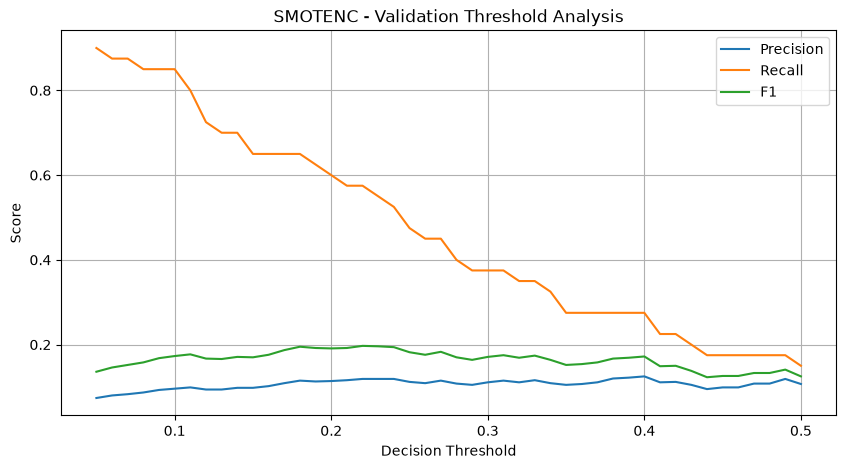

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)
plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)
plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    label="F1"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("SMOTENC - Validation Threshold Analysis")
plt.legend()
plt.grid(True)
plt.show()

In [30]:
print("F1'e göre en iyi 10 eşik:")
print(
    threshold_df
    .sort_values("F1", ascending=False)
    .head(10)
    .to_string(index=False)
)

print("\nPrecision >= 0.15 olan eşikler:")
print(
    threshold_df[threshold_df["Precision"] >= 0.15]
    .sort_values("F1", ascending=False)
    .head(10)
    .to_string(index=False)
)

F1'e göre en iyi 10 eşik:
 Threshold  Precision  Recall    F1
      0.22      0.119   0.575 0.197
      0.23      0.119   0.550 0.196
      0.18      0.115   0.650 0.195
      0.24      0.119   0.525 0.194
      0.19      0.113   0.625 0.192
      0.21      0.116   0.575 0.192
      0.20      0.114   0.600 0.191
      0.17      0.109   0.650 0.187
      0.27      0.115   0.450 0.183
      0.25      0.112   0.475 0.182

Precision >= 0.15 olan eşikler:
Empty DataFrame
Columns: [Threshold, Precision, Recall, F1]
Index: []


In [31]:
from imblearn.ensemble import BalancedRandomForestClassifier

print("Balanced Random Forest hazır.")

Balanced Random Forest hazır.


In [32]:
brf_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", BalancedRandomForestClassifier(
        n_estimators=300,
        sampling_strategy="all",
        replacement=True,
        random_state=42,
        n_jobs=-1
    ))
])

brf_model.fit(X_train_mi, y_train_mi)

print("Balanced Random Forest modeli eğitildi.")

Balanced Random Forest modeli eğitildi.


In [33]:
y_val_brf_proba = brf_model.predict_proba(X_val_mi)[:, 1]

thresholds = np.arange(0.05, 0.51, 0.01)
brf_results = []

for threshold in thresholds:
    y_val_pred = (y_val_brf_proba >= threshold).astype(int)

    brf_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val_mi, y_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val_mi, y_val_pred, zero_division=0
        ),
        "F1": f1_score(
            y_val_mi, y_val_pred, zero_division=0
        )
    })

brf_df = pd.DataFrame(brf_results).round(3)

print("F1'e göre en iyi 10 eşik:")
print(
    brf_df.sort_values("F1", ascending=False)
    .head(10)
    .to_string(index=False)
)

print("\nValidation ROC-AUC:",
      round(roc_auc_score(y_val_mi, y_val_brf_proba), 3))

print("Validation PR-AUC:",
      round(average_precision_score(y_val_mi, y_val_brf_proba), 3))

F1'e göre en iyi 10 eşik:
 Threshold  Precision  Recall    F1
      0.49      0.134   0.675 0.223
      0.50      0.130   0.625 0.215
      0.48      0.127   0.675 0.213
      0.47      0.125   0.700 0.212
      0.46      0.123   0.725 0.210
      0.45      0.118   0.725 0.204
      0.44      0.116   0.725 0.199
      0.43      0.109   0.725 0.189
      0.42      0.104   0.725 0.182
      0.41      0.097   0.725 0.171

Validation ROC-AUC: 0.781
Validation PR-AUC: 0.129


In [34]:
best_threshold_brf = 0.49

y_test_brf_proba = brf_model.predict_proba(X_test_mi)[:, 1]
y_test_brf_pred = (
    y_test_brf_proba >= best_threshold_brf
).astype(int)

print("Seçilen eşik:", best_threshold_brf)
print("Accuracy:", round(
    accuracy_score(y_test_mi, y_test_brf_pred), 3
))
print("Precision:", round(
    precision_score(y_test_mi, y_test_brf_pred, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test_mi, y_test_brf_pred, zero_division=0), 3
))
print("F1:", round(
    f1_score(y_test_mi, y_test_brf_pred, zero_division=0), 3
))
print("ROC-AUC:", round(
    roc_auc_score(y_test_mi, y_test_brf_proba), 3
))
print("PR-AUC:", round(
    average_precision_score(y_test_mi, y_test_brf_proba), 3
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_mi, y_test_brf_pred))

Seçilen eşik: 0.49
Accuracy: 0.8
Precision: 0.109
Recall: 0.512
F1: 0.179
ROC-AUC: 0.792
PR-AUC: 0.116

Confusion Matrix:
[[746 172]
 [ 20  21]]


In [35]:
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60]

threshold_comparison = []

for threshold in thresholds:
    y_pred = (y_val_v2_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_mi, y_pred, labels=[0, 1]
    ).ravel()

    threshold_comparison.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val_mi, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val_mi, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_val_mi, y_pred, zero_division=0
        ),
        "False Positives": fp,
        "True Positives": tp,
        "False Negatives": fn,
        "True Negatives": tn
    })

threshold_comparison_df = pd.DataFrame(
    threshold_comparison
).round(3)

print(threshold_comparison_df.to_string(index=False))

 Threshold  Precision  Recall    F1  False Positives  True Positives  False Negatives  True Negatives
      0.20      0.114   0.600 0.191              187              24               16             731
      0.25      0.116   0.500 0.189              152              20               20             766
      0.30      0.110   0.375 0.170              121              15               25             797
      0.35      0.101   0.275 0.148               98              11               29             820
      0.40      0.124   0.275 0.171               78              11               29             840
      0.45      0.097   0.175 0.125               65               7               33             853
      0.50      0.121   0.175 0.143               51               7               33             867
      0.60      0.147   0.125 0.135               29               5               35             889


In [36]:
# Validation olasılıkları
baseline_val_proba = baseline_model.predict_proba(X_val_mi)[:, 1]
smotenc_val_proba = smotenc_pipeline_v2.predict_proba(X_val_mi)[:, 1]

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60]

comparison = []

models = {
    "Baseline": baseline_val_proba,
    "SMOTENC": smotenc_val_proba
}

for model_name, probabilities in models.items():
    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val_mi, predictions, labels=[0, 1]
        ).ravel()

        comparison.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val_mi, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val_mi, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_val_mi, predictions, zero_division=0
            ),
            "False Positives": fp,
            "True Positives": tp,
            "False Negatives": fn
        })

comparison_df = pd.DataFrame(comparison).round(3)

print(comparison_df.to_string(index=False))

   Model  Threshold  Precision  Recall    F1  False Positives  True Positives  False Negatives
Baseline       0.20      0.111   0.225 0.149               72               9               31
Baseline       0.25      0.093   0.125 0.106               49               5               35
Baseline       0.30      0.083   0.075 0.079               33               3               37
Baseline       0.35      0.130   0.075 0.095               20               3               37
Baseline       0.40      0.105   0.050 0.068               17               2               38
Baseline       0.45      0.182   0.050 0.078                9               2               38
Baseline       0.50      0.286   0.050 0.085                5               2               38
Baseline       0.60      0.500   0.025 0.048                1               1               39
 SMOTENC       0.20      0.114   0.600 0.191              187              24               16
 SMOTENC       0.25      0.116   0.500 0.189      

In [37]:
# Temel demografik ve vücut ölçümü özellikleri
reduced_features = [
    "RIDAGEYR",   # Yaş
    "RIAGENDR",   # Cinsiyet
    "RIDRETH3",   # Etnik grup
    "BMXBMI",     # BMI
    "BMXWAIST",   # Bel çevresi
    "SMQ020"      # Sigara kullanımı
]

X_train_reduced = X_train_mi[reduced_features].copy()
X_val_reduced = X_val_mi[reduced_features].copy()

print("Özellik sayısı:", len(reduced_features))
print("Eğitim boyutu:", X_train_reduced.shape)
print("Validation boyutu:", X_val_reduced.shape)

Özellik sayısı: 6
Eğitim boyutu: (2874, 6)
Validation boyutu: (958, 6)


In [38]:
reduced_numeric_features = [
    "RIDAGEYR", "BMXBMI", "BMXWAIST"
]

reduced_categorical_features = [
    "RIAGENDR", "RIDRETH3", "SMQ020"
]

reduced_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            reduced_numeric_features
        ),
        (
            "cat",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="most_frequent"))
            ]),
            reduced_categorical_features
        )
    ],
    verbose_feature_names_out=False
).set_output(transform="pandas")

reduced_sampler = SMOTENC(
    categorical_features=reduced_categorical_features,
    random_state=42,
    k_neighbors=5
)

reduced_encoder = ColumnTransformer(
    transformers=[
        ("num", "passthrough", reduced_numeric_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            reduced_categorical_features
        )
    ],
    verbose_feature_names_out=False
)

reduced_model = ImbPipeline(steps=[
    ("preprocessor", reduced_preprocessor),
    ("sampler", reduced_sampler),
    ("encoder", reduced_encoder),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ))
])

reduced_model.fit(X_train_reduced, y_train_mi)

print("Reduced SMOTENC modeli eğitildi.")

Reduced SMOTENC modeli eğitildi.


In [39]:
y_val_reduced_proba = reduced_model.predict_proba(
    X_val_reduced
)[:, 1]

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60]

reduced_results = []

for threshold in thresholds:
    y_pred = (y_val_reduced_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_mi, y_pred, labels=[0, 1]
    ).ravel()

    reduced_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val_mi, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val_mi, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_val_mi, y_pred, zero_division=0
        ),
        "False Positives": fp,
        "True Positives": tp,
        "False Negatives": fn
    })

reduced_results_df = pd.DataFrame(reduced_results).round(3)

print(reduced_results_df.to_string(index=False))
print(
    "\nValidation ROC-AUC:",
    round(roc_auc_score(y_val_mi, y_val_reduced_proba), 3)
)
print(
    "Validation PR-AUC:",
    round(average_precision_score(y_val_mi, y_val_reduced_proba), 3)
)

 Threshold  Precision  Recall    F1  False Positives  True Positives  False Negatives
      0.20      0.076   0.425 0.129              206              17               23
      0.25      0.078   0.375 0.129              178              15               25
      0.30      0.076   0.325 0.123              159              13               27
      0.35      0.059   0.225 0.093              144               9               31
      0.40      0.062   0.200 0.094              122               8               32
      0.45      0.071   0.200 0.105              105               8               32
      0.50      0.074   0.175 0.104               88               7               33
      0.60      0.043   0.075 0.055               66               3               37

Validation ROC-AUC: 0.688
Validation PR-AUC: 0.07


In [40]:
# Düzeltilmiş SMOTENC modelindeki Random Forest
rf_model = smotenc_pipeline_v2.named_steps["classifier"]

# One-hot encoding sonrasındaki özellik isimleri
feature_names = (
    smotenc_pipeline_v2.named_steps["encoder"]
    .get_feature_names_out()
)

# Özellik önemlerini tabloya aktar
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print(importance_df.to_string(index=False))

     Feature  Importance
    RIDAGEYR    0.181660
RIAGENDR_2.0    0.090190
RIAGENDR_1.0    0.087864
    INDFMPIR    0.065587
      SLD012    0.063475
    DR1TPROT    0.061448
    BMXWAIST    0.056029
RIDRETH3_3.0    0.049976
    DR1TKCAL    0.049464
    DR1TFIBE    0.046084
      BMXBMI    0.044963
    DR1TCARB    0.041572
    DR1TSUGR    0.038797
DMDEDUC2_5.0    0.027666
  SMQ020_2.0    0.022568
  SMQ020_1.0    0.022537
DMDEDUC2_4.0    0.014979
DMDEDUC2_3.0    0.008291
RIDRETH3_4.0    0.007074
DMDEDUC2_2.0    0.006724
RIDRETH3_1.0    0.005248
RIDRETH3_7.0    0.002450
RIDRETH3_2.0    0.002408
DMDEDUC2_1.0    0.001995
RIDRETH3_6.0    0.000952


In [41]:
features_no_diet = [
    "RIDAGEYR",
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2",
    "INDFMPIR",
    "BMXBMI",
    "BMXWAIST",
    "SLD012",
    "SMQ020"
]

X_train_no_diet = X_train_mi[features_no_diet].copy()
X_val_no_diet = X_val_mi[features_no_diet].copy()

numeric_no_diet = [
    "RIDAGEYR", "INDFMPIR", "BMXBMI",
    "BMXWAIST", "SLD012"
]

categorical_no_diet = [
    "RIAGENDR", "RIDRETH3", "DMDEDUC2", "SMQ020"
]

print("Özellik sayısı:", len(features_no_diet))
print("Eğitim verisi:", X_train_no_diet.shape)
print("Validation verisi:", X_val_no_diet.shape)

Özellik sayısı: 9
Eğitim verisi: (2874, 9)
Validation verisi: (958, 9)


In [42]:
from imblearn.pipeline import Pipeline as ImbPipeline

reduced_preprocessor_v2 = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_no_diet),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent"))
        ]), categorical_no_diet)
    ],
    verbose_feature_names_out=False
).set_output(transform="pandas")

reduced_smotenc = SMOTENC(
    categorical_features=categorical_no_diet,
    random_state=42,
    k_neighbors=5
)

reduced_encoder = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_no_diet),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_no_diet)
    ],
    verbose_feature_names_out=False
)

model_no_diet = ImbPipeline([
    ("preprocessor", reduced_preprocessor_v2),
    ("sampler", reduced_smotenc),
    ("encoder", reduced_encoder),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ))
])

model_no_diet.fit(X_train_no_diet, y_train_mi)

print("Beslenme değişkenleri çıkarılmış SMOTENC modeli eğitildi.")

Beslenme değişkenleri çıkarılmış SMOTENC modeli eğitildi.


In [43]:
y_val_no_diet_proba = model_no_diet.predict_proba(X_val_no_diet)[:, 1]

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60]
results_no_diet = []

for threshold in thresholds:
    y_pred = (y_val_no_diet_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_mi, y_pred, labels=[0, 1]
    ).ravel()

    results_no_diet.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val_mi, y_pred, zero_division=0),
        "Recall": recall_score(y_val_mi, y_pred, zero_division=0),
        "F1": f1_score(y_val_mi, y_pred, zero_division=0),
        "False Positives": fp,
        "True Positives": tp,
        "False Negatives": fn
    })

results_no_diet_df = pd.DataFrame(results_no_diet).round(3)

print(results_no_diet_df.to_string(index=False))
print("\nValidation ROC-AUC:",
      round(roc_auc_score(y_val_mi, y_val_no_diet_proba), 3))
print("Validation PR-AUC:",
      round(average_precision_score(y_val_mi, y_val_no_diet_proba), 3))

 Threshold  Precision  Recall    F1  False Positives  True Positives  False Negatives
      0.20      0.099   0.450 0.163              163              18               22
      0.25      0.101   0.375 0.160              133              15               25
      0.30      0.096   0.300 0.145              113              12               28
      0.35      0.088   0.225 0.127               93               9               31
      0.40      0.094   0.200 0.128               77               8               32
      0.45      0.081   0.150 0.105               68               6               34
      0.50      0.094   0.150 0.115               58               6               34
      0.60      0.100   0.100 0.100               36               4               36

Validation ROC-AUC: 0.73
Validation PR-AUC: 0.087


In [45]:
from sklearn.impute import KNNImputer

In [50]:
knn_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("scaler", StandardScaler()),
            ("imputer", KNNImputer(
                n_neighbors=10,
                weights="distance"
            ))
        ]), numeric_features),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

knn_model = Pipeline([
    ("preprocessor", knn_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

knn_model.fit(X_train_mi, y_train_mi)

print("KNN imputer modeli eğitildi.")

KNN imputer modeli eğitildi.


In [51]:
# Validation olasılık tahminleri
y_val_knn_proba = knn_model.predict_proba(X_val_mi)[:, 1]

# Varsayılan threshold = 0.50
y_val_knn_pred = (y_val_knn_proba >= 0.50).astype(int)

print("KNN Imputer Modeli")
print("-" * 35)
print("ROC-AUC:",
      round(roc_auc_score(y_val_mi, y_val_knn_proba), 3))
print("PR-AUC:",
      round(average_precision_score(y_val_mi, y_val_knn_proba), 3))
print("Precision:",
      round(precision_score(y_val_mi, y_val_knn_pred, zero_division=0), 3))
print("Recall:",
      round(recall_score(y_val_mi, y_val_knn_pred, zero_division=0), 3))
print("F1:",
      round(f1_score(y_val_mi, y_val_knn_pred, zero_division=0), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_mi, y_val_knn_pred))

KNN Imputer Modeli
-----------------------------------
ROC-AUC: 0.75
PR-AUC: 0.106
Precision: 0.2
Recall: 0.05
F1: 0.08

Confusion Matrix:
[[910   8]
 [ 38   2]]


In [52]:
thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

knn_results = []

for threshold in thresholds:
    y_pred = (y_val_knn_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_mi, y_pred, labels=[0, 1]
    ).ravel()

    knn_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val_mi, y_pred, zero_division=0),
        "Recall": recall_score(y_val_mi, y_pred, zero_division=0),
        "F1": f1_score(y_val_mi, y_pred, zero_division=0),
        "False Positives": fp,
        "True Positives": tp,
        "False Negatives": fn
    })

knn_results_df = pd.DataFrame(knn_results).round(3)
print(knn_results_df.to_string(index=False))

 Threshold  Precision  Recall    F1  False Positives  True Positives  False Negatives
      0.05      0.075   0.850 0.138              417              34                6
      0.10      0.094   0.700 0.166              269              28               12
      0.15      0.102   0.500 0.169              177              20               20
      0.20      0.110   0.375 0.170              121              15               25
      0.25      0.115   0.250 0.157               77              10               30
      0.30      0.103   0.150 0.122               52               6               34
      0.40      0.103   0.075 0.087               26               3               37
      0.50      0.200   0.050 0.080                8               2               38


In [49]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import ExtraTreesRegressor

In [53]:
rf_imputer = IterativeImputer(
    estimator=ExtraTreesRegressor(
        n_estimators=50,
        random_state=42,
        n_jobs=-1
    ),
    max_iter=5,
    random_state=42
)

rf_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("scaler", StandardScaler()),
            ("imputer", rf_imputer)
        ]), numeric_features),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

rf_imputation_model = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_imputation_model.fit(X_train_mi, y_train_mi)

print("Random Forest tabanlı doldurma modeli eğitildi.")

c:\BitirmeProjesi\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


Random Forest tabanlı doldurma modeli eğitildi.


In [54]:
y_val_rf_imp_proba = rf_imputation_model.predict_proba(X_val_mi)[:, 1]
y_val_rf_imp_pred = (y_val_rf_imp_proba >= 0.50).astype(int)

print("Random Forest tabanlı doldurma")
print("-" * 40)

print("ROC-AUC:",
      round(roc_auc_score(y_val_mi, y_val_rf_imp_proba), 3))
print("PR-AUC:",
      round(average_precision_score(y_val_mi, y_val_rf_imp_proba), 3))
print("Precision:",
      round(precision_score(y_val_mi, y_val_rf_imp_pred, zero_division=0), 3))
print("Recall:",
      round(recall_score(y_val_mi, y_val_rf_imp_pred, zero_division=0), 3))
print("F1:",
      round(f1_score(y_val_mi, y_val_rf_imp_pred, zero_division=0), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_mi, y_val_rf_imp_pred))

Random Forest tabanlı doldurma
----------------------------------------
ROC-AUC: 0.741
PR-AUC: 0.105
Precision: 0.2
Recall: 0.05
F1: 0.08

Confusion Matrix:
[[910   8]
 [ 38   2]]


In [55]:
thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

comparison = []

for name, probabilities in [
    ("KNN", y_val_knn_proba),
    ("Tree-based imputation", y_val_rf_imp_proba)
]:
    for threshold in thresholds:
        y_pred = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val_mi, y_pred, labels=[0, 1]
        ).ravel()

        comparison.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val_mi, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_val_mi, y_pred, zero_division=0
            ),
            "F1": f1_score(
                y_val_mi, y_pred, zero_division=0
            ),
            "FP": fp,
            "TP": tp,
            "FN": fn
        })

comparison_df = pd.DataFrame(comparison).round(3)
print(comparison_df.to_string(index=False))

                Model  Threshold  Precision  Recall    F1  FP  TP  FN
                  KNN       0.05      0.075   0.850 0.138 417  34   6
                  KNN       0.10      0.094   0.700 0.166 269  28  12
                  KNN       0.15      0.102   0.500 0.169 177  20  20
                  KNN       0.20      0.110   0.375 0.170 121  15  25
                  KNN       0.25      0.115   0.250 0.157  77  10  30
                  KNN       0.30      0.103   0.150 0.122  52   6  34
                  KNN       0.40      0.103   0.075 0.087  26   3  37
                  KNN       0.50      0.200   0.050 0.080   8   2  38
Tree-based imputation       0.05      0.077   0.850 0.141 408  34   6
Tree-based imputation       0.10      0.090   0.625 0.158 252  25  15
Tree-based imputation       0.15      0.097   0.475 0.161 177  19  21
Tree-based imputation       0.20      0.120   0.375 0.182 110  15  25
Tree-based imputation       0.25      0.119   0.250 0.161  74  10  30
Tree-based imputatio

In [56]:
knn_no_weight_model = Pipeline([
    ("preprocessor", clone(knn_preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ))
])

knn_no_weight_model.fit(X_train_mi, y_train_mi)

print("KNN doldurma + sınıf ağırlığı olmadan model eğitildi.")

KNN doldurma + sınıf ağırlığı olmadan model eğitildi.


In [57]:
# Validation olasılıkları
y_val_knn_nw_proba = knn_no_weight_model.predict_proba(X_val_mi)[:, 1]

# Threshold = 0.50
y_val_knn_nw_pred = (y_val_knn_nw_proba >= 0.50).astype(int)

print("KNN + class_weight=None")
print("-" * 35)

print("ROC-AUC:",
      round(roc_auc_score(y_val_mi, y_val_knn_nw_proba), 3))
print("PR-AUC:",
      round(average_precision_score(y_val_mi, y_val_knn_nw_proba), 3))
print("Precision:",
      round(precision_score(y_val_mi, y_val_knn_nw_pred, zero_division=0), 3))
print("Recall:",
      round(recall_score(y_val_mi, y_val_knn_nw_pred, zero_division=0), 3))
print("F1:",
      round(f1_score(y_val_mi, y_val_knn_nw_pred, zero_division=0), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_mi, y_val_knn_nw_pred))

KNN + class_weight=None
-----------------------------------
ROC-AUC: 0.778
PR-AUC: 0.12
Precision: 0.0
Recall: 0.0
F1: 0.0

Confusion Matrix:
[[918   0]
 [ 40   0]]


In [58]:
thresholds = [0.01, 0.02, 0.03, 0.05, 0.07, 0.10, 0.15, 0.20]

results_nw = []

for threshold in thresholds:
    y_pred = (y_val_knn_nw_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_mi, y_pred, labels=[0, 1]
    ).ravel()

    results_nw.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val_mi, y_pred, zero_division=0),
        "Recall": recall_score(y_val_mi, y_pred, zero_division=0),
        "F1": f1_score(y_val_mi, y_pred, zero_division=0),
        "FP": fp,
        "TP": tp,
        "FN": fn
    })

results_nw_df = pd.DataFrame(results_nw).round(3)
print(results_nw_df.to_string(index=False))

 Threshold  Precision  Recall    F1  FP  TP  FN
      0.01      0.052   0.950 0.099 690  38   2
      0.02      0.065   0.900 0.120 522  36   4
      0.03      0.082   0.900 0.150 405  36   4
      0.05      0.093   0.750 0.165 294  30  10
      0.07      0.114   0.700 0.196 217  28  12
      0.10      0.123   0.525 0.199 150  21  19
      0.15      0.143   0.275 0.188  66  11  29
      0.20      0.138   0.100 0.116  25   4  36


In [59]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [60]:
hgb_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("scaler", StandardScaler()),
            ("imputer", KNNImputer(
                n_neighbors=5,
                weights="distance"
            ))
        ]), numeric_features),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]), categorical_features)
    ],
    sparse_threshold=0
)

hgb_model = Pipeline([
    ("preprocessor", hgb_preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        random_state=42
    ))
])

hgb_model.fit(X_train_mi, y_train_mi)

print("HistGradientBoosting modeli eğitildi.")

HistGradientBoosting modeli eğitildi.


In [61]:
y_val_hgb_proba = hgb_model.predict_proba(X_val_mi)[:, 1]
y_val_hgb_pred = (y_val_hgb_proba >= 0.50).astype(int)

print("HistGradientBoosting")
print("-" * 35)
print("ROC-AUC:",
      round(roc_auc_score(y_val_mi, y_val_hgb_proba), 3))
print("PR-AUC:",
      round(average_precision_score(y_val_mi, y_val_hgb_proba), 3))
print("Precision:",
      round(precision_score(y_val_mi, y_val_hgb_pred, zero_division=0), 3))
print("Recall:",
      round(recall_score(y_val_mi, y_val_hgb_pred, zero_division=0), 3))
print("F1:",
      round(f1_score(y_val_mi, y_val_hgb_pred, zero_division=0), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_mi, y_val_hgb_pred))

HistGradientBoosting
-----------------------------------
ROC-AUC: 0.726
PR-AUC: 0.088
Precision: 0.0
Recall: 0.0
F1: 0.0

Confusion Matrix:
[[917   1]
 [ 40   0]]


In [62]:
import importlib.util

print("XGBoost kurulu mu:", importlib.util.find_spec("xgboost") is not None)

XGBoost kurulu mu: False


In [63]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   -----------------

In [64]:
import xgboost as xgb

print("XGBoost sürümü:", xgb.__version__)

XGBoost sürümü: 3.4.1


In [65]:
xgb_preprocessor = clone(knn_preprocessor)

xgb_model = Pipeline([
    ("preprocessor", xgb_preprocessor),
    ("classifier", xgb.XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train_mi, y_train_mi)

print("XGBoost modeli eğitildi.")

XGBoost modeli eğitildi.


In [66]:
y_val_xgb_proba = xgb_model.predict_proba(X_val_mi)[:, 1]
y_val_xgb_pred = (y_val_xgb_proba >= 0.50).astype(int)

print("XGBoost")
print("-" * 35)

print("ROC-AUC:",
      round(roc_auc_score(y_val_mi, y_val_xgb_proba), 3))
print("PR-AUC:",
      round(average_precision_score(y_val_mi, y_val_xgb_proba), 3))
print("Precision:",
      round(precision_score(y_val_mi, y_val_xgb_pred, zero_division=0), 3))
print("Recall:",
      round(recall_score(y_val_mi, y_val_xgb_pred, zero_division=0), 3))
print("F1:",
      round(f1_score(y_val_mi, y_val_xgb_pred, zero_division=0), 3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_mi, y_val_xgb_pred))

XGBoost
-----------------------------------
ROC-AUC: 0.759
PR-AUC: 0.112
Precision: 0.0
Recall: 0.0
F1: 0.0

Confusion Matrix:
[[917   1]
 [ 40   0]]


In [67]:
thresholds = [0.01, 0.02, 0.03, 0.05, 0.07, 0.10, 0.15, 0.20]

xgb_results = []

for threshold in thresholds:
    y_pred = (y_val_xgb_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_mi, y_pred, labels=[0, 1]
    ).ravel()

    xgb_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val_mi, y_pred, zero_division=0),
        "Recall": recall_score(y_val_mi, y_pred, zero_division=0),
        "F1": f1_score(y_val_mi, y_pred, zero_division=0),
        "FP": fp,
        "TP": tp,
        "FN": fn
    })

xgb_results_df = pd.DataFrame(xgb_results).round(3)
print(xgb_results_df.to_string(index=False))

 Threshold  Precision  Recall    F1  FP  TP  FN
      0.01      0.064   0.925 0.120 540  37   3
      0.02      0.081   0.875 0.148 398  35   5
      0.03      0.088   0.775 0.158 322  31   9
      0.05      0.099   0.600 0.170 219  24  16
      0.07      0.102   0.450 0.166 159  18  22
      0.10      0.120   0.350 0.178 103  14  26
      0.15      0.121   0.175 0.143  51   7  33
      0.20      0.156   0.125 0.139  27   5  35


In [68]:
missing_report = pd.DataFrame({
    "Missing Count": X_train_mi.isna().sum(),
    "Missing Percent": (X_train_mi.isna().mean() * 100).round(2)
}).sort_values("Missing Percent", ascending=False)

print(missing_report.to_string())

          Missing Count  Missing Percent
INDFMPIR            335            11.66
BMXWAIST            120             4.18
BMXBMI               35             1.22
SLD012               25             0.87
SMQ020                4             0.14
RIAGENDR              0             0.00
RIDRETH3              0             0.00
DMDEDUC2              0             0.00
RIDAGEYR              0             0.00
DR1TKCAL              0             0.00
DR1TPROT              0             0.00
DR1TCARB              0             0.00
DR1TSUGR              0             0.00
DR1TFIBE              0             0.00


In [69]:
print("INDFMPIR — eğitim verisi")
print("Toplam örnek:", len(X_train_mi))
print("Eksik değer:", X_train_mi["INDFMPIR"].isna().sum())
print("Mevcut değer:", X_train_mi["INDFMPIR"].notna().sum())

print("\nDağılım:")
print(X_train_mi["INDFMPIR"].describe().round(2))

INDFMPIR — eğitim verisi
Toplam örnek: 2874
Eksik değer: 335
Mevcut değer: 2539

Dağılım:
count    2539.00
mean        3.03
std         1.65
min         0.00
25%         1.52
50%         3.00
75%         5.00
max         5.00
Name: INDFMPIR, dtype: float64
